# 03 - Exploratory Data Analysis (EDA)

## Step 1: Load the data

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/campaigns_features.csv")
print(df.shape)
df.head()

(166665, 26)


,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,...,Year,Month,Channel_Instagram,Channel_Email,Channel_Google,Channel_Facebook,Channel_YouTube,Channel_WhatsApp,Channel_Count,Profit_Flag
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515.0,...,2025,4,0,0,0,0,1,1,2,1
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247.0,...,2025,4,0,0,0,0,1,0,1,1
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055.0,...,2025,1,0,0,1,0,1,1,3,1
3,NY-CMP-1003,Email,Working Women,18,"YouTube, Facebook, Instagram",88114,8413,2231,947,376906.0,...,2025,6,1,0,0,1,1,0,3,1
4,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296.0,...,2024,12,1,0,0,1,0,0,2,1


In [3]:
df.info()
print("Total nulls:", df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 166665 entries, 0 to 166664
Data columns (total 26 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Campaign_ID        166665 non-null  str    
 1   Campaign_Type      166665 non-null  str    
 2   Target_Audience    166665 non-null  str    
 3   Duration           166665 non-null  int64  
 4   Channel_Used       166665 non-null  str    
 5   Impressions        166665 non-null  int64  
 6   Clicks             166665 non-null  int64  
 7   Leads              166665 non-null  int64  
 8   Conversions        166665 non-null  int64  
 9   Revenue            166665 non-null  float64
 10  Acquisition_Cost   166665 non-null  float64
 11  ROI                166665 non-null  float64
 12  Language           166665 non-null  str    
 13  Engagement_Score   166665 non-null  float64
 14  Customer_Segment   166665 non-null  str    
 15  Brand              166665 non-null  str    
 16  Year         

In [4]:
df.describe().round(2)

,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score,Year,Month,Channel_Instagram,Channel_Email,Channel_Google,Channel_Facebook,Channel_YouTube,Channel_WhatsApp,Channel_Count,Profit_Flag
count,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00,166665.00
mean,17.46,55070.94,4646.63,1852.94,1027.03,512868.69,375.15,2.69,13.76,2024.45,6.63,0.32,0.32,0.32,0.32,0.32,0.32,1.90,0.76
std,7.31,25313.05,3102.54,1397.72,855.11,486072.80,533.61,4.54,6.17,0.50,3.46,0.47,0.47,0.47,0.47,0.47,0.47,0.91,0.43
min,5.00,10001.00,202.00,48.00,17.00,3895.00,8.18,-1.00,2.56,2024.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,11.00,33783.00,2185.00,809.00,403.00,178710.00,107.39,0.05,8.65,2024.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00
50%,17.00,55113.00,3908.00,1476.00,775.00,359247.00,208.59,1.23,13.59,2024.00,7.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,1.00
75%,24.00,76427.00,6510.00,2525.00,1396.00,681380.00,425.45,3.57,18.53,2025.00,10.00,1.00,1.00,1.00,1.00,1.00,1.00,3.00,1.00
max,30.00,100000.00,14944.00,8876.00,6686.00,4579910.00,15473.16,157.80,30.99,2025.00,12.00,1.00,1.00,1.00,1.00,1.00,1.00,3.00,1.00


## Step 2: Profit vs Loss balance
If one class is much bigger, accuracy alone can look good by luck. Remember this number for the classification step.

Profit_Flag
1    126871
0     39794
Name: count, dtype: int64
Profit_Flag
1    0.761
0    0.239
Name: proportion, dtype: float64


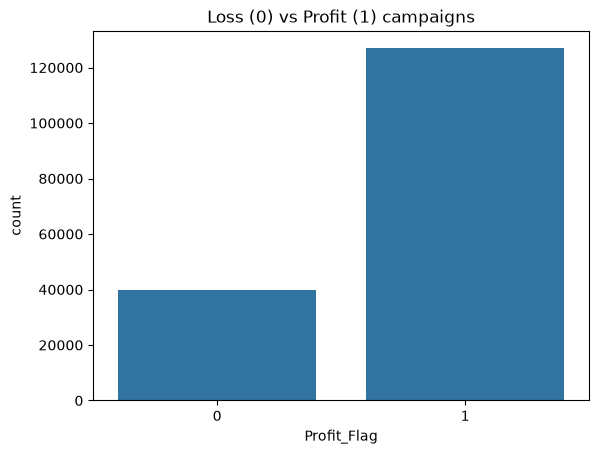

In [5]:
print(df["Profit_Flag"].value_counts())
print(df["Profit_Flag"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="Profit_Flag")
plt.title("Loss (0) vs Profit (1) campaigns")
plt.show()

## Step 3: Brand-wise performance

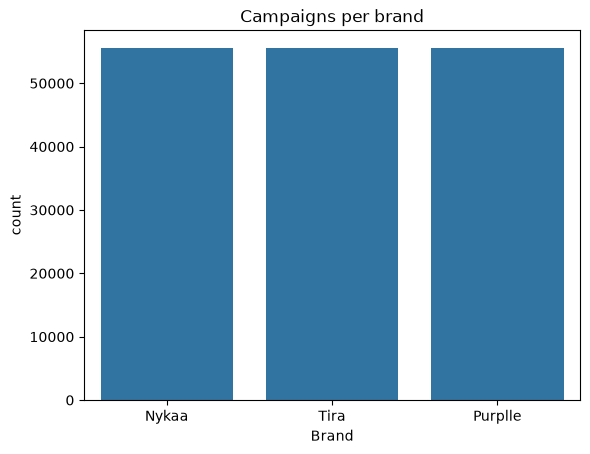

,Revenue,Acquisition_Cost,ROI,Profit_Flag
Brand,,,,
Nykaa,514928.30,376.46,2.72,0.76
Purplle,512675.63,375.59,2.69,0.76
Tira,511002.14,373.40,2.68,0.76


In [6]:
sns.countplot(data=df, x="Brand")
plt.title("Campaigns per brand")
plt.show()

brand_summary = df.groupby("Brand")[["Revenue", "Acquisition_Cost", "ROI", "Profit_Flag"]].mean().round(2)
brand_summary

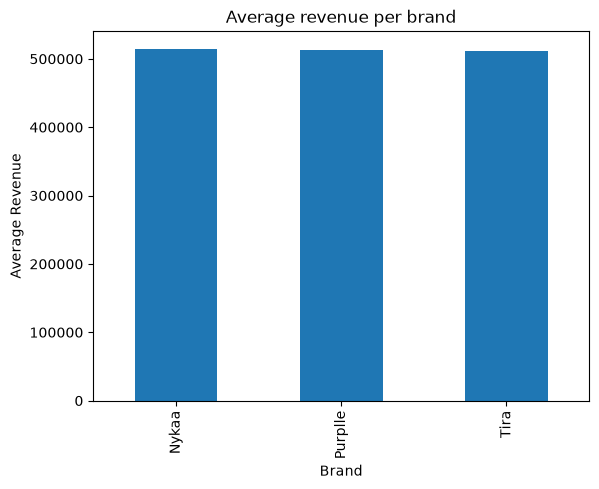

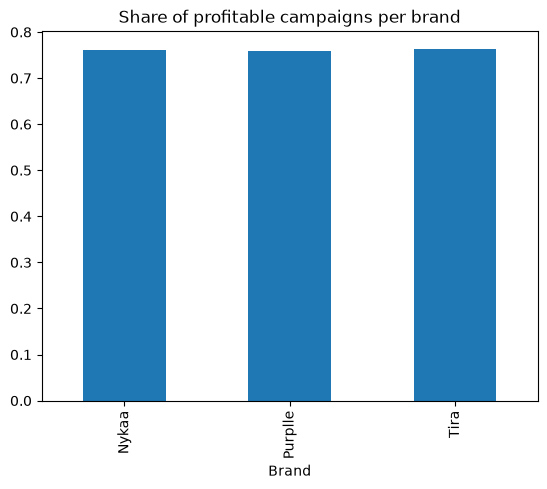

In [7]:
df.groupby("Brand")["Revenue"].mean().plot(kind="bar")
plt.title("Average revenue per brand")
plt.ylabel("Average Revenue")
plt.show()

# Profit_Flag is 1 or 0, so its average is the share of profitable campaigns
df.groupby("Brand")["Profit_Flag"].mean().plot(kind="bar")
plt.title("Share of profitable campaigns per brand")
plt.show()

## Step 4: Top and low performing campaigns
Rows where Conversions is 775 were filled with the median during cleaning, so we leave them out of the rankings.

In [8]:
real_rows = df[df["Conversions"] != 775]

top_roi = real_rows.sort_values("ROI", ascending=False).head(10)
top_roi[["Campaign_ID", "Brand", "Campaign_Type", "Conversions", "Revenue", "Acquisition_Cost", "ROI"]]

,Campaign_ID,Brand,Campaign_Type,Conversions,Revenue,Acquisition_Cost,ROI
100961,TI-CMP-46406,Tira,Social Media,6152,4041864.0,8.18,79.30
12007,NY-CMP-13007,Nykaa,Paid Ads,6686,4579910.0,9.08,74.42
72904,Unknown,Tira,Paid Ads,5358,4045290.0,10.32,72.16
152083,PU-CMP-41973,Purplle,Paid Ads,5114,3467292.0,9.99,66.84
21689,NY-CMP-22689,Nykaa,Influencer,5315,3821485.0,10.68,66.32
48715,NY-CMP-49715,Nykaa,Paid Ads,4664,3717208.0,12.08,64.98
64313,TI-CMP-9758,Tira,Email,4542,3392874.0,11.35,64.80
25356,NY-CMP-26356,Nykaa,Paid Ads,4764,3363384.0,10.84,64.14
140291,PU-CMP-30181,Purplle,SEO,4952,3278224.0,10.19,63.96
119099,PU-CMP-8989,Purplle,SEO,4650,3668850.0,12.62,61.54


In [9]:
top_revenue = df.sort_values("Revenue", ascending=False).head(10)
top_revenue[["Campaign_ID", "Brand", "Conversions", "Revenue", "Acquisition_Cost", "ROI"]]

,Campaign_ID,Brand,Conversions,Revenue,Acquisition_Cost,ROI
12007,NY-CMP-13007,Nykaa,6686,4579910.0,9.08,74.42
96864,TI-CMP-42309,Tira,5661,4517478.0,44.89,16.78
43157,NY-CMP-44157,Nykaa,5607,4412709.0,18.08,42.53
132378,PU-CMP-22268,Purplle,6036,4345920.0,33.45,20.53
37379,NY-CMP-38379,Nykaa,5910,4326120.0,50.76,13.42
88288,TI-CMP-33733,Tira,5820,4277700.0,47.03,14.63
5741,NY-CMP-6741,Nykaa,5678,4263879.0,22.47,32.42
107343,TI-CMP-52788,Tira,5309,4231273.0,18.58,41.90
82351,TI-CMP-27796,Tira,5788,4207876.0,35.83,19.29
146404,PU-CMP-36294,Purplle,5379,4195620.0,20.35,37.33


In [10]:
low_roi = real_rows.sort_values("ROI").head(10)
low_roi[["Campaign_ID", "Brand", "Conversions", "Revenue", "Acquisition_Cost", "ROI"]]

,Campaign_ID,Brand,Conversions,Revenue,Acquisition_Cost,ROI
83594,TI-CMP-29039,Tira,19,3895.0,15038.00,-0.99
75293,TI-CMP-20738,Tira,22,6072.0,12723.55,-0.98
110756,Unknown,Tira,17,6987.0,14802.41,-0.97
63494,TI-CMP-8939,Tira,37,8695.0,6717.78,-0.97
142138,PU-CMP-32028,Purplle,42,9072.0,6471.33,-0.97
70567,TI-CMP-16012,Tira,35,9625.0,8183.09,-0.97
23406,NY-CMP-24406,Nykaa,27,6183.0,6805.56,-0.97
55914,TI-CMP-1359,Tira,36,9180.0,8310.08,-0.97
134874,PU-CMP-24764,Purplle,35,7350.0,7850.57,-0.97
119377,PU-CMP-9267,Purplle,21,9702.0,12109.05,-0.96


## Step 5: What makes a campaign profitable?

In [11]:
loss = df[df["Profit_Flag"] == 0]
profit = df[df["Profit_Flag"] == 1]

print("LOSS campaigns, average:")
print(loss[["Conversions", "Acquisition_Cost", "Revenue", "Engagement_Score"]].mean().round(1))

print("PROFIT campaigns, average:")
print(profit[["Conversions", "Acquisition_Cost", "Revenue", "Engagement_Score"]].mean().round(1))

LOSS campaigns, average:
Conversions            318.0
Acquisition_Cost       966.5
Revenue             119933.8
Engagement_Score         9.5
dtype: float64
PROFIT campaigns, average:
Conversions           1249.4
Acquisition_Cost       189.7
Revenue             636115.6
Engagement_Score        15.1
dtype: float64


## Step 6: Distributions

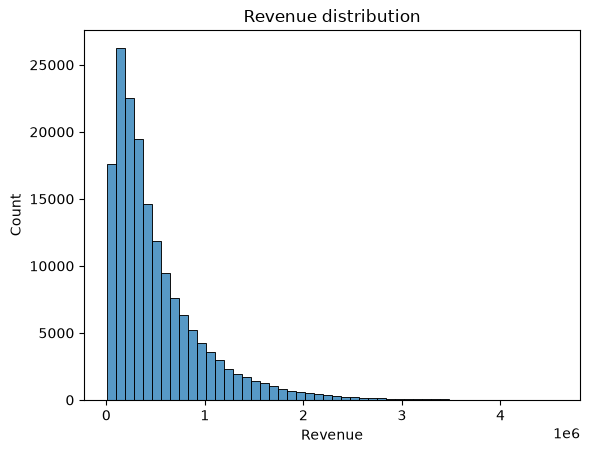

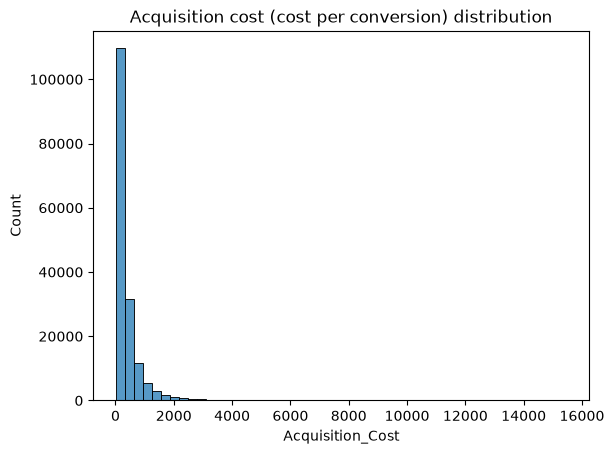

In [12]:
sns.histplot(df["Revenue"], bins=50)
plt.title("Revenue distribution")
plt.show()

sns.histplot(df["Acquisition_Cost"], bins=50)
plt.title("Acquisition cost (cost per conversion) distribution")
plt.show()

## Step 7: Correlation heatmap

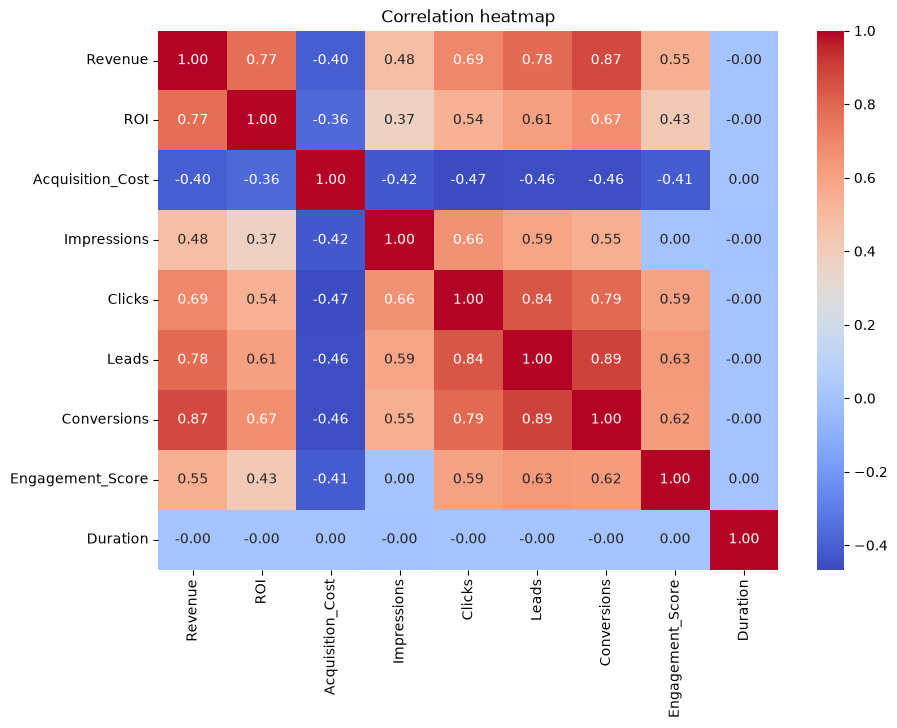

In [13]:
number_columns = ["Revenue", "ROI", "Acquisition_Cost", "Impressions", "Clicks",
                  "Leads", "Conversions", "Engagement_Score", "Duration"]

plt.figure(figsize=(10, 7))
sns.heatmap(df[number_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

## Step 8: Spend, clicks, revenue and ROI
There are over 160,000 rows, so we plot a random sample of 3,000. It looks the same and is much faster.

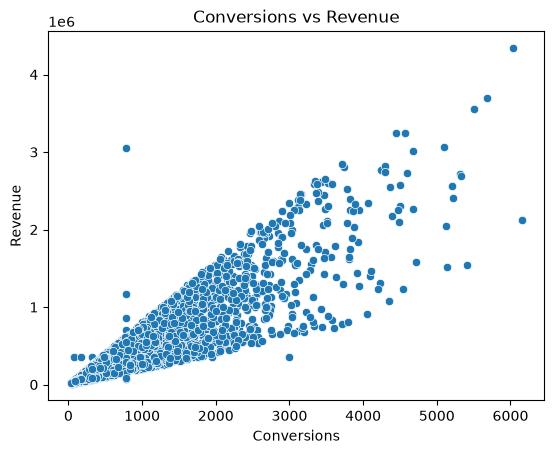

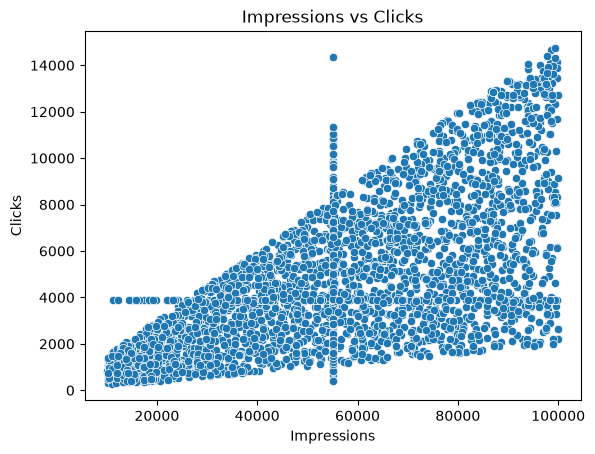

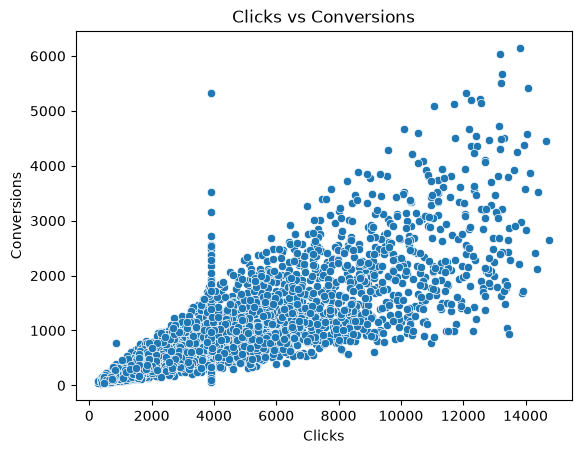

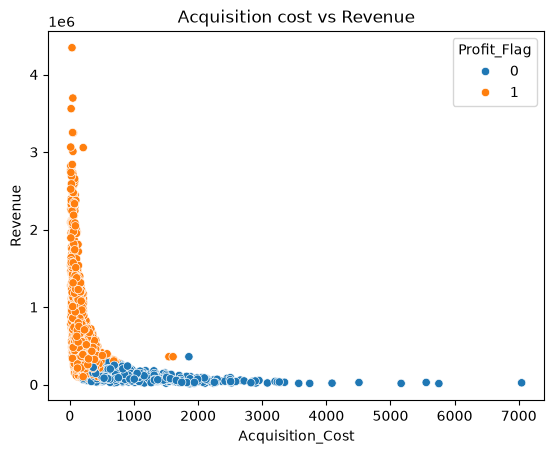

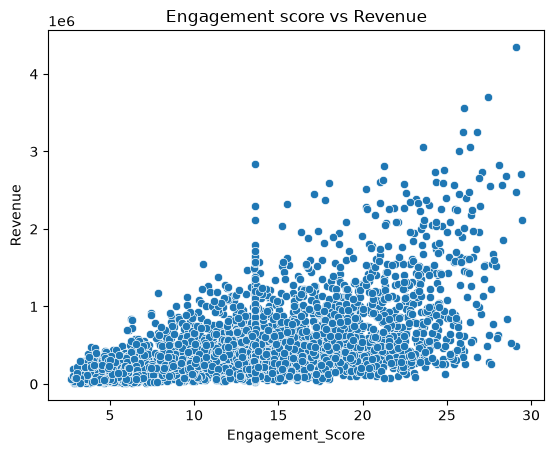

In [14]:
sample = df.sample(3000, random_state=42)

sns.scatterplot(data=sample, x="Conversions", y="Revenue")
plt.title("Conversions vs Revenue")
plt.show()

sns.scatterplot(data=sample, x="Impressions", y="Clicks")
plt.title("Impressions vs Clicks")
plt.show()

sns.scatterplot(data=sample, x="Clicks", y="Conversions")
plt.title("Clicks vs Conversions")
plt.show()

sns.scatterplot(data=sample, x="Acquisition_Cost", y="Revenue", hue="Profit_Flag")
plt.title("Acquisition cost vs Revenue")
plt.show()

sns.scatterplot(data=sample, x="Engagement_Score", y="Revenue")
plt.title("Engagement score vs Revenue")
plt.show()

## Step 9: Channel-wise effectiveness
A campaign can use several channels, so the groups overlap. That is normal for multi-label data.

In [15]:
insta = df[df["Channel_Instagram"] == 1]
email = df[df["Channel_Email"] == 1]
google = df[df["Channel_Google"] == 1]
facebook = df[df["Channel_Facebook"] == 1]
youtube = df[df["Channel_YouTube"] == 1]
whatsapp = df[df["Channel_WhatsApp"] == 1]

channel_table = pd.DataFrame({
    "Channel": ["Instagram", "Email", "Google", "Facebook", "YouTube", "WhatsApp"],
    "Campaigns": [len(insta), len(email), len(google), len(facebook), len(youtube), len(whatsapp)],
    "Avg_Revenue": [insta["Revenue"].mean(), email["Revenue"].mean(), google["Revenue"].mean(),
                    facebook["Revenue"].mean(), youtube["Revenue"].mean(), whatsapp["Revenue"].mean()],
    "Avg_ROI": [insta["ROI"].mean(), email["ROI"].mean(), google["ROI"].mean(),
                facebook["ROI"].mean(), youtube["ROI"].mean(), whatsapp["ROI"].mean()],
    "Profit_Share": [insta["Profit_Flag"].mean(), email["Profit_Flag"].mean(), google["Profit_Flag"].mean(),
                     facebook["Profit_Flag"].mean(), youtube["Profit_Flag"].mean(), whatsapp["Profit_Flag"].mean()],
}).round(2)

channel_table

,Channel,Campaigns,Avg_Revenue,Avg_ROI,Profit_Share
0,Instagram,52890,516036.92,2.73,0.76
1,Email,52848,515955.01,2.73,0.76
2,Google,52831,511172.83,2.69,0.76
3,Facebook,52814,512742.66,2.69,0.76
4,YouTube,52781,510785.51,2.67,0.76
5,WhatsApp,52724,512519.74,2.69,0.76


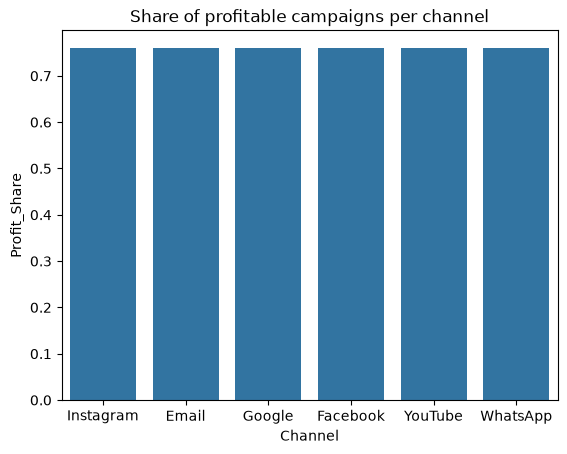

,Revenue,ROI,Profit_Flag
Channel_Count,,,
0,506686.64,2.65,0.75
1,513052.70,2.69,0.76
2,513401.32,2.69,0.76
3,513121.77,2.70,0.76


In [16]:
sns.barplot(data=channel_table, x="Channel", y="Profit_Share")
plt.title("Share of profitable campaigns per channel")
plt.show()

# Does using more channels help?
df.groupby("Channel_Count")[["Revenue", "ROI", "Profit_Flag"]].mean().round(2)

## Step 10: Campaign type, audience, segment and language

In [17]:
df.groupby("Campaign_Type")[["Revenue", "ROI", "Profit_Flag"]].mean().round(2)

,Revenue,ROI,Profit_Flag
Campaign_Type,,,
Email,512623.65,2.70,0.76
Influencer,509226.48,2.65,0.76
Paid Ads,517626.79,2.72,0.76
SEO,509536.43,2.69,0.76
Social Media,514761.55,2.72,0.77
Unknown,515123.77,2.69,0.76


In [18]:
df.groupby("Target_Audience")[["Revenue", "ROI", "Profit_Flag"]].mean().round(2)

,Revenue,ROI,Profit_Flag
Target_Audience,,,
College Students,511632.63,2.67,0.76
Premium Shoppers,513644.99,2.71,0.76
Tier 2 City Customers,513381.50,2.71,0.76
Unknown,518473.93,2.70,0.77
Working Women,511978.66,2.69,0.76
Youth,512251.47,2.69,0.76


In [19]:
df.groupby("Customer_Segment")[["Revenue", "ROI", "Profit_Flag"]].mean().round(2)

,Revenue,ROI,Profit_Flag
Customer_Segment,,,
College Students,513110.65,2.71,0.76
Premium Shoppers,509747.49,2.66,0.76
Tier 2 City Customers,514344.86,2.69,0.76
Unknown,512052.04,2.65,0.77
Working Women,514381.98,2.72,0.76
Youth,512952.76,2.70,0.76


In [20]:
df.groupby("Language")[["Revenue", "ROI", "Profit_Flag"]].mean().round(2)

,Revenue,ROI,Profit_Flag
Language,,,
Bengali,510977.50,2.67,0.76
English,513441.22,2.70,0.76
Hindi,513773.75,2.71,0.76
Tamil,514472.20,2.72,0.76
Unknown,507173.92,2.62,0.75


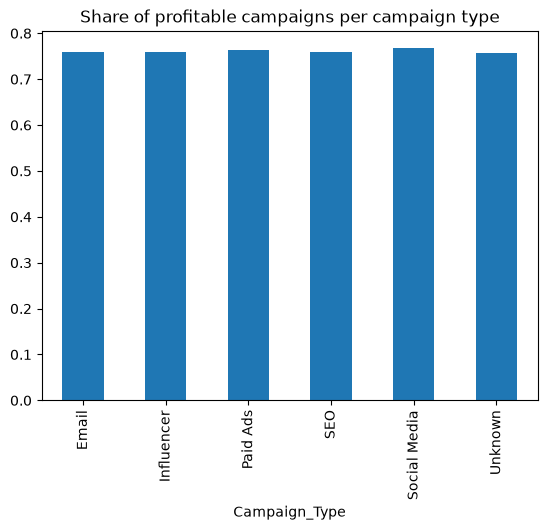

In [21]:
df.groupby("Campaign_Type")["Profit_Flag"].mean().plot(kind="bar")
plt.title("Share of profitable campaigns per campaign type")
plt.show()

## Step 11: Time trends

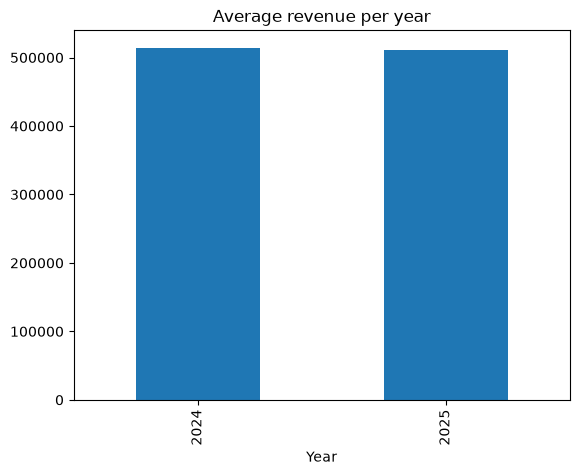

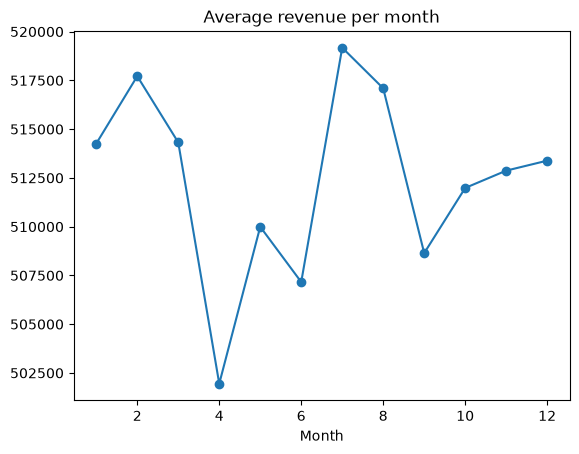

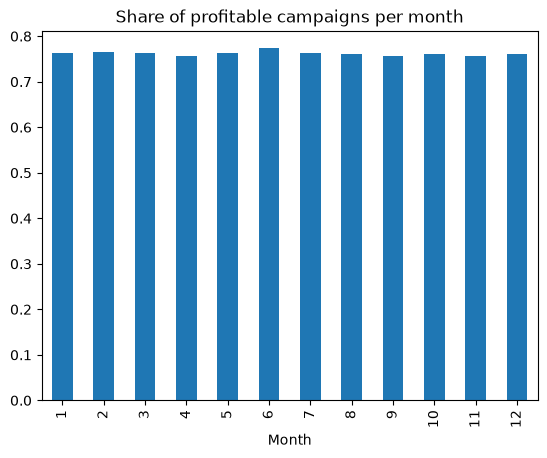

In [22]:
df.groupby("Year")["Revenue"].mean().plot(kind="bar")
plt.title("Average revenue per year")
plt.show()

df.groupby("Month")["Revenue"].mean().plot(kind="line", marker="o")
plt.title("Average revenue per month")
plt.show()

df.groupby("Month")["Profit_Flag"].mean().plot(kind="bar")
plt.title("Share of profitable campaigns per month")
plt.show()

## Step 12: EDA findings (write these in your report)
Check each point against your own output before using it.

1. **About 76% of campaigns are profitable and 24% make a loss.** Remember that guessing "Profit" every time already gives 76% accuracy.
2. **The three brands are almost identical.** Average ROI is 2.68 to 2.72 and the profit share is 0.76 for Nykaa, Purplle and Tira.
3. **Channels, campaign types, segments, languages, months and years show almost no difference** (profit share about 0.76 everywhere), so these are weak predictors.
4. **The strongest link with Revenue is Conversions (0.87), then Leads (0.78) and Clicks (0.69).** Duration has no link (0.00).
5. **Loss campaigns have a much higher cost per conversion** (about 966 vs 190 for profit campaigns) and **far fewer conversions** (about 318 vs 1,249).
6. **Recommendation:** focus on lowering the cost per conversion and raising conversion volume, instead of switching brand or channel.